In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, NullLocator
import seaborn as sns
import sklearn 
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
import hyperimpute
from hyperimpute.plugins.imputers import Imputers


In [2]:
# load the dataset
df = pd.read_csv(r"D:\University\summer semester\project\datasets\adult.csv")
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


None

In [3]:
# removal of duplicate rows
duplicates = df[df.duplicated(keep=False)]
df.drop_duplicates(inplace=True)

# replacing ? with nan and drop them
df = df.replace("?", np.nan)
df = df.dropna()

# dropping unnecessary columns
df = df.drop(columns=["fnlwgt", "educational-num"])
df_gt = df.copy()
display(df_gt.info())

<class 'pandas.core.frame.DataFrame'>
Index: 45175 entries, 0 to 48841
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45175 non-null  int64 
 1   workclass       45175 non-null  object
 2   education       45175 non-null  object
 3   marital-status  45175 non-null  object
 4   occupation      45175 non-null  object
 5   relationship    45175 non-null  object
 6   race            45175 non-null  object
 7   gender          45175 non-null  object
 8   capital-gain    45175 non-null  int64 
 9   capital-loss    45175 non-null  int64 
 10  hours-per-week  45175 non-null  int64 
 11  native-country  45175 non-null  object
 12  income          45175 non-null  object
dtypes: int64(4), object(9)
memory usage: 4.8+ MB


None

In [4]:
# Split into Numerical and Categorical datasets
df_gt_num = df_gt.select_dtypes(include=["number"]).copy()
df_gt_cat = df_gt.select_dtypes(include=["object"]).copy()

In [17]:
# scale numerical data
min_max_scaler = MinMaxScaler()
df_gt_num_scaled = pd.DataFrame(
    min_max_scaler.fit_transform(df_gt_num),
    columns=df_gt_num.columns,
    index=df_gt_num.index,
)

In [5]:
# defining the missing rates
missing_rates = [0.0175, 1.0, 10.0]

In [6]:
# a function injecting missing values using uniform random sampling (mcar)
def uniform_missing(df: pd.DataFrame, missing_rate: float, seed: int = 42):
    
    np.random.seed(seed)
    total_cells = df.size

    # Calculate exact number of cells to mask
    n_missing = int(np.round(total_cells * (missing_rate / 100)))

    # Flat random sample of cell indices
    mask_indexes = np.random.choice(total_cells, size=n_missing, replace=False)

    # Convert flat 1D indices to 2D matrix coordinates (row, col)
    mask_rows, mask_cols = np.unravel_index(mask_indexes, df.shape)

    # Create boolean mask
    mask = np.zeros(df.shape, dtype=bool)
    mask[mask_rows, mask_cols] = True

    # Create incomplete copy
    df_incomplete = df.copy()
    for row, col in zip(mask_rows, mask_cols):
        # .iat is faster than .iloc or .loc
        df_incomplete.iat[row, col] = np.nan

    return df_incomplete, mask

In [18]:
# a function for evaluating model performance on numerical data using rmse and mae
def evaluate_imputation_num (df_gt, df_imputed, mask_num_df):
    results = []
    for col in df_gt.columns:
        # create a boolean Series for this column using the mask that was built after injecting missing vlaues
        m = mask_num_df[col]  
        # Skip columns that had no missing values
        if m.sum() == 0:
            continue
        # returns a numpy array of actual values in this column
        actual = df_gt.loc[m, col].values
        # returns a numpy array of predicted values in this column
        pred   = df_imputed.loc[m, col].values
        
        mae  = mean_absolute_error(actual, pred)
        rmse = np.sqrt(mean_squared_error(actual, pred))
        
        results.append({
            "Column":        col,
            "MAE":           mae,
            "RMSE":          rmse,
            "Missing_Count": int(m.sum()),
        })
    return pd.DataFrame(results)

In [19]:
# a function for evaluating model performance on categorical data using accuracy and error rate
def evaluate_imputation_cat(df_gt, df_imputed, mask_cat_df):
    results = []
    total_missing = 0
    total_matches = 0
    
    for col in df_gt.columns:
        # create a boolean Series for this column using the mask that was built after injecting missing vlaues
        m = mask_cat_df[col].values
        # Skip columns that had no missing values
        missing_count = m.sum()
        if missing_count == 0: 
            continue

        # returns a numpy array of actual values in this column    
        actual = df_gt.loc[m, col]
        # returns a numpy array of predicted values in this column
        pred = df_imputed.loc[m, col]
        
        matches = (actual == pred).sum()
        accuracy = matches / missing_count
        
        total_missing += missing_count
        total_matches += matches
        
        results.append({
            "Column": col,
            "Accuracy": accuracy,
            "Error_Rate": 1.0 - accuracy,
            "Missing_Count": int(missing_count)
        })

    return pd.DataFrame(results)

In [20]:
# A function determining the number of iterations for mice
def choose_max_iter(df_incomplete: pd.DataFrame, min_iter: int = 10):
    corr = df_incomplete.corr().abs()
    print(corr)
    # exclude self-correlation from the max
    np.fill_diagonal(corr.values, 0)
    max_corr = corr.max().max()
    if max_corr > 0.6:
        # need more than 10 cycles when strongly correlated
        max_iter = max(min_iter, 20)
        print(f"\nMax |correlation| > 0.6.\nA maximum of {max_iter} iterations needed.")
    else:
        max_iter = min_iter
        print(f"\nMax |correlation| <= 0.6.\nA maximum of {max_iter} iterations needed.")
    return max_iter

In [11]:
# global results container setup
num_results = []  # Store numerical metrics
cat_results = []  # Store categorical metrics

In [21]:
# mice on numerical data

for rate in missing_rates:
    print(f"\n{'='*25} Missing Rate: {rate}% {'='*25}")
    
    # mask
    df_incomplete, mask = uniform_missing(df_gt_num_scaled, missing_rate=rate, seed=42)
    mask_df = pd.DataFrame(mask, columns=df_gt_num_scaled.columns, index=df_gt_num_scaled.index)
    
    # impute using mice
    max_iter = choose_max_iter(df_incomplete)
    mice_imputer = Imputers().get(
        "mice", 
        n_imputations=5, 
        max_iter=max_iter, 
        tol=0.001, 
        initial_strategy=0, 
        imputation_order=0, 
        random_state=42
    )   
    df_imputed_raw = mice_imputer.fit_transform(df_incomplete.copy())
    df_imputed = pd.DataFrame(
        df_imputed_raw.values if isinstance(df_imputed_raw, pd.DataFrame) else df_imputed_raw,
        columns=df_gt_num_scaled.columns,
        index=df_gt_num_scaled.index
    )
    
    # evaluate
    results_df = evaluate_imputation_num(df_gt_num_scaled, df_imputed, mask_df)
    
    print("\nper-column imputation performance :\n")
    print(f"{'Column':<18} {'MAE':<10} {'RMSE':<10} {'Missing_Count':<13}")
    for _, row in results_df.iterrows():
        print(f"{row['Column']:<18} {row['MAE']:<10.5f} {row['RMSE']:<10.5f} {int(row['Missing_Count']):<13}")
        
    print("\nMean metrics across columns:")
    print(results_df[["MAE", "RMSE"]].mean())

    num_results.append({
        "Model": "MICE",  
        "Missing_Rate": rate,
        "RMSE": results_df["RMSE"].mean(),
        "MAE": results_df["MAE"].mean(),
    })


========================= Missing Rate: 0.0175% =========================
                     age  capital-gain  capital-loss  hours-per-week
age             1.000000      0.079642      0.059293        0.101586
capital-gain    0.079642      1.000000      0.032142        0.083880
capital-loss    0.059293      0.032142      1.000000        0.054157
hours-per-week  0.101586      0.083880      0.054157        1.000000

Max |correlation| <= 0.6.
A maximum of 10 iterations needed.

per-column imputation performance :

Column             MAE        RMSE       Missing_Count
age                0.16068    0.17949    7            
capital-gain       0.01595    0.02121    11           
capital-loss       0.03242    0.03978    9            
hours-per-week     0.09836    0.11669    5            

Mean metrics across columns:
MAE     0.076852
RMSE    0.089291
dtype: float64

========================= Missing Rate: 1.0% =========================
                     age  capital-gain  capital-loss  

In [22]:
# missforest on numerical data

missforest_imputer = Imputers().get(
    "missforest",
    n_estimators=50,      
    max_iter=10,          
    imputation_order=0,    
    initial_strategy=0,    
    random_state=42        
)

for rate in missing_rates:
    print(f"\n{'='*25} Missing Rate: {rate}% {'='*25}")
    
    # mask
    df_incomplete, mask = uniform_missing(df_gt_num_scaled, missing_rate=rate, seed=42)
    mask_df = pd.DataFrame(mask, columns=df_gt_num_scaled.columns, index=df_gt_num_scaled.index)
    
    # impute using missforest
    df_imputed_raw = missforest_imputer.fit_transform(df_incomplete.copy())
    df_imputed = pd.DataFrame(
        df_imputed_raw.values if isinstance(df_imputed_raw, pd.DataFrame) else df_imputed_raw,
        columns=df_gt_num_scaled.columns,
        index=df_gt_num_scaled.index
    )
    
    # evaluate
    results_df = evaluate_imputation_num(df_gt_num_scaled, df_imputed, mask_df)
    
    print("\nPer-column imputation performance:\n")
    print(f"{'Column':<18} {'MAE':<10} {'RMSE':<10} {'Missing_Count':<13}")
    for _, row in results_df.iterrows():
        print(f"{row['Column']:<18} {row['MAE']:<10.5f} {row['RMSE']:<10.5f} {int(row['Missing_Count']):<13}")
        
    print("\nMean metrics across columns:")
    print(results_df[["MAE", "RMSE"]].mean())

    num_results.append({
        "Model": "MISSFOREST",  
        "Missing_Rate": rate,
        "RMSE": results_df["RMSE"].mean(),
        "MAE": results_df["MAE"].mean(),
    })



========================= Missing Rate: 0.0175% =========================

Per-column imputation performance:

Column             MAE        RMSE       Missing_Count
age                0.11853    0.15422    7            
capital-gain       0.01298    0.02116    11           
capital-loss       0.02629    0.02788    9            
hours-per-week     0.08078    0.09989    5            

Mean metrics across columns:
MAE     0.059643
RMSE    0.075788
dtype: float64

========================= Missing Rate: 1.0% =========================

Per-column imputation performance:

Column             MAE        RMSE       Missing_Count
age                0.14112    0.17524    451          
capital-gain       0.02040    0.07258    439          
capital-loss       0.03595    0.08417    492          
hours-per-week     0.07712    0.11941    425          

Mean metrics across columns:
MAE     0.068646
RMSE    0.112851
dtype: float64

========================= Missing Rate: 10.0% ========================

In [23]:
# gain on numerical data

for rate in missing_rates:
    print(f"\n{'='*25} Missing Rate: {rate}% {'='*25}")
    
    # mask
    df_incomplete, mask = uniform_missing(df_gt_num_scaled, missing_rate=rate, seed=42)
    mask_df = pd.DataFrame(mask, columns=df_gt_num_scaled.columns, index=df_gt_num_scaled.index)
    
    # impute using gain
    gain_imputer = Imputers().get(
        "gain",
        batch_size=128,        # Batch size for training step
        n_epochs=1000,         # Number of training iterations (paper default: 1000-5000)
        hint_rate=0.9,         # The discriminator is told the truth for 90% of data
        loss_alpha=10,         # Weight of MSE reconstruction loss (alpha)
        random_state=42        # Reproducibility seed
    )
    
    df_imputed_raw = gain_imputer.fit_transform(df_incomplete.copy())
    df_imputed = pd.DataFrame(
        df_imputed_raw.values if isinstance(df_imputed_raw, pd.DataFrame) else df_imputed_raw,
        columns=df_gt_num_scaled.columns,
        index=df_gt_num_scaled.index
    )
    
    # 3. evaluate
    results_df = evaluate_imputation_num(df_gt_num_scaled, df_imputed, mask_df)
    
    print("\nPer-column imputation performance:\n")
    print(f"{'Column':<18} {'MAE':<10} {'RMSE':<10} {'Missing_Count':<13}")
    for _, row in results_df.iterrows():
        print(f"{row['Column']:<18} {row['MAE']:<10.5f} {row['RMSE']:<10.5f} {int(row['Missing_Count']):<13}")
        
    print("\nMean metrics across columns:")
    print(results_df[["MAE", "RMSE"]].mean())

    num_results.append({
        "Model": "GAIN",  
        "Missing_Rate": rate,
        "RMSE": results_df["RMSE"].mean(),
        "MAE": results_df["MAE"].mean(),
    })

   


========================= Missing Rate: 0.0175% =========================

Per-column imputation performance:

Column             MAE        RMSE       Missing_Count
age                0.13292    0.18055    7            
capital-gain       0.01914    0.02287    11           
capital-loss       0.08203    0.08474    9            
hours-per-week     0.33136    0.34093    5            

Mean metrics across columns:
MAE     0.141360
RMSE    0.157272
dtype: float64

========================= Missing Rate: 1.0% =========================

Per-column imputation performance:

Column             MAE        RMSE       Missing_Count
age                0.15438    0.20333    451          
capital-gain       0.03242    0.07458    439          
capital-loss       0.06802    0.09606    492          
hours-per-week     0.24190    0.26980    425          

Mean metrics across columns:
MAE     0.124182
RMSE    0.160943
dtype: float64

========================= Missing Rate: 10.0% ========================

In [15]:
# missforest on categorical data 

for rate in missing_rates:
    print( f"\n{'='*25} Missing Rate: {rate}% {'='*25}")

    # mask
    df_incomplete, mask = uniform_missing(df_gt_cat, missing_rate=rate, seed=42)
    # turn the mask into a dataframe
    mask_df = pd.DataFrame(mask, columns=df_gt_cat.columns, index=df_gt_cat.index)

    # impute using missforest
    missforest_imputer = Imputers().get(
        "missforest",
        n_estimators=50,      
        max_iter=10,          
        imputation_order=0,    
        initial_strategy=0,    
        random_state=42        
    )

    df_imputed_raw = missforest_imputer.fit_transform(df_incomplete.copy())

    df_imputed_cat = pd.DataFrame(
        df_imputed_raw.values if isinstance(df_imputed_raw, pd.DataFrame) else df_imputed_raw,
        columns=df_gt_cat.columns,
        index=df_gt_cat.index
    )

    # evaluate
    results_df = evaluate_imputation_cat(df_gt_cat, df_imputed_cat, mask_df)

    print("\nPer-column Imputation Performance:\n")
    print(f"{'Column':<20} {'Accuracy':<16} {'Error_Rate':<16} {'Missing_Count':<16}")
    print("-" * 68)

    for _, row in results_df.iterrows():
        print(f"{row['Column']:<20} {row['Accuracy']:<16.5f} {row['Error_Rate']:<16.5f} {int(row['Missing_Count']):<16}")


    print("\nMean metrics across columns:")
    print(results_df[["Accuracy", "Error_Rate"]].mean())

    cat_results.append({
        "Model": "MISSFOREST",  
        "Missing_Rate": rate,
        "Accuracy": results_df["Accuracy"].mean(),
        "Error_Rate": results_df["Error_Rate"].mean(),
    })


========================= Missing Rate: 0.0175% =========================

Per-column Imputation Performance:

Column               Accuracy         Error_Rate       Missing_Count   
--------------------------------------------------------------------
workclass            0.85714          0.14286          7               
education            0.00000          1.00000          8               
marital-status       0.40000          0.60000          5               
occupation           0.00000          1.00000          7               
relationship         0.54545          0.45455          11              
race                 0.00000          1.00000          10              
gender               0.60000          0.40000          10              
native-country       0.00000          1.00000          5               
income               0.87500          0.12500          8               

Mean metrics across columns:
Accuracy      0.364177
Error_Rate    0.635823
dtype: float64

=======

In [16]:
# most frequent on categorical data

for rate in missing_rates:
    print(f"\n{'='*25} Mode Imputer | Missing Rate: {rate}% {'='*25}")

    # mask
    df_incomplete, mask = uniform_missing(df_gt_cat, missing_rate=rate, seed=42)
    mask_df = pd.DataFrame(mask, columns=df_gt_cat.columns, index=df_gt_cat.index)

    # impute using mode
    mode_imputer = SimpleImputer(strategy="most_frequent")
    df_imputed_raw = mode_imputer.fit_transform(df_incomplete.copy())
    df_imputed = pd.DataFrame(
        df_imputed_raw.values if isinstance(df_imputed_raw, pd.DataFrame) else df_imputed_raw,
        columns=df_gt_cat.columns,
        index=df_gt_cat.index,
    )

    # evaluate
    results_df = evaluate_imputation_cat(df_gt_cat, df_imputed, mask_df)

    print("\nPer-column Imputation Performance:\n")
    print(f"{'Column':<20} {'Accuracy':<16} {'Error_Rate':<16} {'Missing_Count':<16}")
    print("-" * 68)

    for _, row in results_df.iterrows():
        print(f"{row['Column']:<20} {row['Accuracy']:<16.5f} {row['Error_Rate']:<16.5f} {int(row['Missing_Count']):<16}")

    print("\nMean metrics across columns:")
    print(results_df[["Accuracy", "Error_Rate"]].mean())

    cat_results.append({
        "Model": "MODE",  
        "Missing_Rate": rate,
        "Accuracy": results_df["Accuracy"].mean(),
        "Error_Rate": results_df["Error_Rate"].mean(),
    })



========================= Mode Imputer | Missing Rate: 0.0175% =========================

Per-column Imputation Performance:

Column               Accuracy         Error_Rate       Missing_Count   
--------------------------------------------------------------------
workclass            1.00000          0.00000          7               
education            0.12500          0.87500          8               
marital-status       0.40000          0.60000          5               
occupation           0.14286          0.85714          7               
relationship         0.45455          0.54545          11              
race                 0.90000          0.10000          10              
gender               0.50000          0.50000          10              
native-country       1.00000          0.00000          5               
income               0.87500          0.12500          8               

Mean metrics across columns:
Accuracy      0.599711
Error_Rate    0.400289
dtype: f

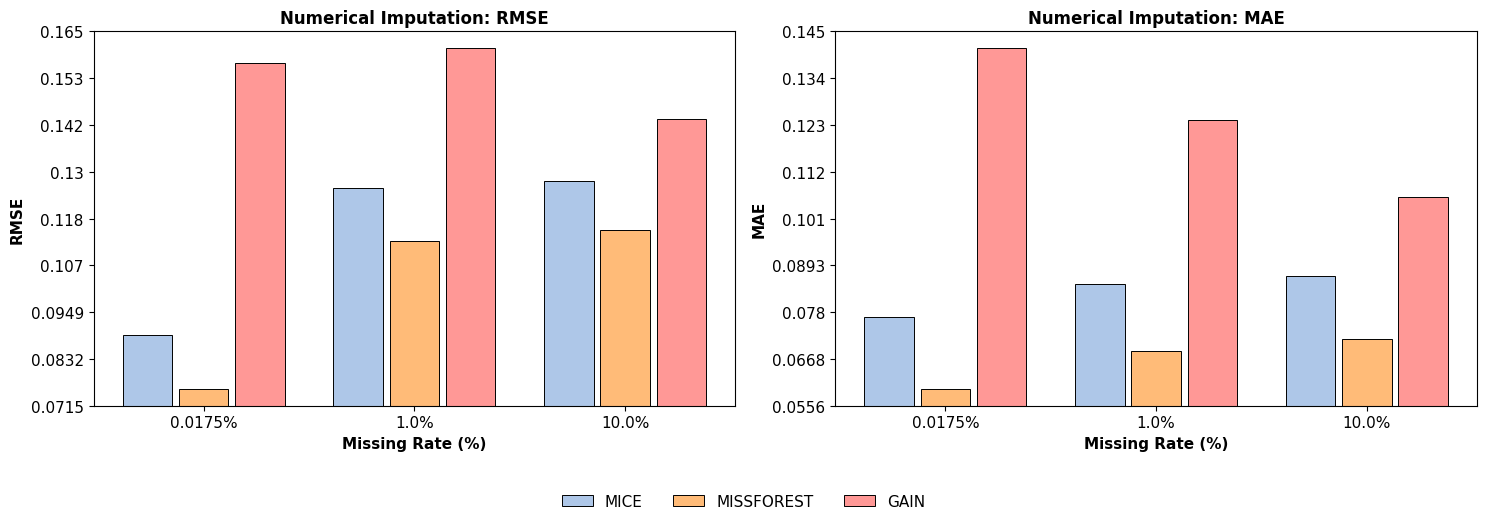

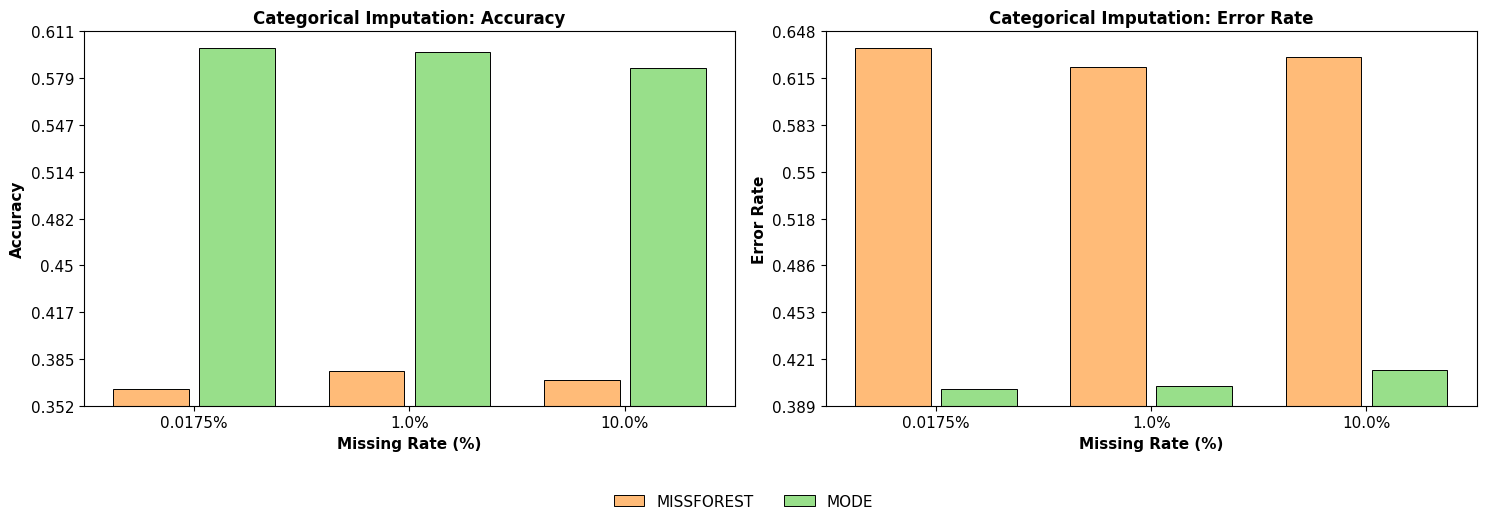

In [ ]:
# Convert result lists to DataFrames
df_num_results = pd.DataFrame(num_results)
df_cat_results = pd.DataFrame(cat_results)

rates_ticks = missing_rates

# styling 
STYLE = {
    "MICE":       "#aec7e8",
    "MISSFOREST": "#ffbb78",
    "GAIN":       "#ff9896",
    "MODE":       "#98df8a",  
}

plt.rcParams.update({"font.size": 11})

def nice_ticks(ax, vals, n=9):
    # Sets exactly n ticks on the y-axis with plain decimal labels.
    vals = [v for v in vals if not np.isnan(v)]
    if not vals:
        return ax
    vmin, vmax = min(vals), max(vals)
    
    # add a slight padding so bars don't touch the top/bottom edges
    pad = (vmax - vmin) * 0.05 if vmax != vmin else vmin * 0.05
    vmin_adj = max(0, vmin - pad)
    vmax_adj = min(1.0, vmax + pad) if vmax <= 1.0 else vmax + pad

    ticks = np.linspace(vmin_adj, vmax_adj, n)
    ax.set_ylim(vmin_adj, vmax_adj)
    ax.set_yticks(ticks)
    
    # plain decimal format (e.g., 0.1, 0.05) instead of scientific notation
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    # disable minor ticks safely
    ax.yaxis.set_minor_locator(NullLocator())
    return ax

def grouped_bars(ax, df, metric, ylabel, title):
    # grouped bar plot with clean column aesthetics and 9 distinct y-axis ticks.
    models = [m for m in STYLE if m in df["Model"].unique()]
    if not models:
        models = df["Model"].unique().tolist()
        
    x = np.arange(len(rates_ticks))
    n_models = len(models)
    width = 0.8 / n_models

    all_vals = []
    for i, model in enumerate(models):
        sub = df[df["Model"] == model]
        vals = []
        for r in rates_ticks:
            match = sub[np.isclose(sub["Missing_Rate"], r)][metric]
            vals.append(float(match.iloc[0]) if not match.empty else np.nan)
        all_vals.extend(vals)
        
        ax.bar(
            x + i * width - 0.4 + width / 2,
            vals,
            width=width * 0.88,
            label=model,
            color=STYLE.get(model, "#aec7e8"),
            edgecolor="black",
            linewidth=0.7,
        )

    # apply exactly 9 numbers on the left axis
    nice_ticks(ax, all_vals, n=9)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{r}%" for r in rates_ticks])
    ax.set_xlabel("Missing Rate (%)", fontweight="bold")
    ax.set_ylabel(ylabel, fontweight="bold")
    ax.set_title(title, fontsize=12, fontweight="bold")
    return ax



# numerical: rmse & mae
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.subplots_adjust(wspace=0.35)

grouped_bars(axes[0], df_num_results, "RMSE", "RMSE", title="Numerical Imputation: RMSE")
grouped_bars(axes[1], df_num_results, "MAE",  "MAE",  title="Numerical Imputation: MAE")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="lower center", ncol=len(labels),
               frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.06))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()



# categorical: accuracy & error rate (missforest vs mode)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.subplots_adjust(wspace=0.35)

grouped_bars(axes[0], df_cat_results, "Accuracy",   "Accuracy",   title="Categorical Imputation: Accuracy")
grouped_bars(axes[1], df_cat_results, "Error_Rate", "Error Rate", title="Categorical Imputation: Error Rate")

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="lower center", ncol=len(labels),
               frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.06))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()
